**Autism Diagnosis Prediction Project**

Life cycle of Machine learning Project

* Understanding the Problem Statement
* Data Collection
* Exploratory data analysis
* Data Cleaning
* Data Pre-Processing
* Model Training
* Choose best model



**About**

Autism spectrum disorder (ASD) is a developmental disability caused by differences in the brain. People with ASD often have problems with social communication and interaction, and restricted or repetitive behaviors or interests. People with ASD may also have different ways of learning, moving, or paying attention

**1) Problem Statement**

•	Autism Spectrum Disorder (ASD) diagnosis requires clinical assessment from specialists, which is time-consuming and costly.\
•	As the number of individuals needing screening is huge, healthcare providers need Machine Learning models to pre-screen potential ASD cases based on their AQ-10 test results and demographic data.

In this project we are going to use the data given to build a Classification model:

•	This model is to check if a person is likely to have Autism (ASD) or not, based on the given dataset.\
•	This can be used to recommend whether an individual should be referred for a full clinical autism assessment, based on certain screening criteria which influence the decision.

**2) Data Collection**

•	The dataset originates from the "Autism Screening Adult" dataset, created by Fadi Thabtah and officially published on the UCI Machine Learning Repository on December 23, 2017.\
•	DOI: 10.24432/C5F019

•	License: Creative Commons Attribution 4.0 International (CC BY 4.0)

•	Original UCI dataset: 704 instances, 20 features (Integer type, Classification task, Social Science domain)\
•	Data was collected using the AQ-10 (Autism Spectrum Quotient – 10 items) screening questionnaire, based on the tool developed by the Autism Research Centre, University of Cambridge, and gathered via the ASDTest mobile application.

The dataset was later adapted and re-hosted on Kaggle under the name "AutismDiagnosis" by user Konika Rani (konikarani), split into:\
	•	train.csv: 800 records\
	•	test.csv: 200 records\
	•	Total: ~1,000 records, 22 columns

Key features:

•	A1_Score to A10_Score — binary responses (0/1) to the AQ-10 screening questions\
•	Demographics — age, gender, ethnicity, country of residence\
•	Medical/family history — jaundice at birth, family member with autism (austim)\
•	Screening context — used_app_before, relation, result (total AQ score)\
•	Target variable: Class/ASD (0 = No, 1 = Yes)

https://archive.ics.uci.edu/dataset/426/autism+screening+adult \
https://www.kaggle.com/datasets/konikarani/autismdiagnosis

**2.1 Import Data and Required Packages**


Importing Pandas,Numpy,Matplotlib,Seaborn and Warings Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

**Import the CSV Data as Pandas DataFrame**

In [3]:
df = pd.read_csv(r"train.csv")

**Show Top 5 Records**

In [4]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,...,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,...,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,...,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,...,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,...,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


**Shape of the dataset**

In [5]:
df.shape

(800, 22)

**Statistics Summary of the dataset**

In [6]:
df.describe()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.0000,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,28.452118,8.537303,0.201250
std,231.0844,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.310966,4.807676,0.401185
min,1.0000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.718550,-6.137748,0.000000
25%,200.7500,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.198153,5.306575,0.000000
50%,400.5000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.848350,9.605299,0.000000
75%,600.2500,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.865429,12.514484,0.000000
max,800.0000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.461718,15.853126,1.000000


**Check Datatypes in the dataset**

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

**3. EXPLORING DATA**

In [8]:
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('We have {} categorical features : {}'.format(len(categorical_features), categorical_features))


We have 14 numerical features : ['ID', 'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'result', 'Class/ASD']
We have 8 categorical features : ['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before', 'age_desc', 'relation']


In [9]:
for col in categorical_features:
    print(df[col].value_counts(normalize=True)*100)
    print('---------------------------')

gender
m    66.25
f    33.75
Name: proportion, dtype: float64
---------------------------
ethnicity
White-European     32.125
?                  25.375
Middle Eastern     12.125
Asian               8.375
Black               5.875
South Asian         4.250
Pasifika            4.000
Others              3.625
Latino              2.125
Hispanic            1.125
Turkish             0.625
others              0.375
Name: proportion, dtype: float64
---------------------------
jaundice
no     76.875
yes    23.125
Name: proportion, dtype: float64
---------------------------
austim
no     83.625
yes    16.375
Name: proportion, dtype: float64
---------------------------
contry_of_res
United States           16.750
India                   13.500
New Zealand              9.750
United Kingdom           8.375
Jordan                   6.875
United Arab Emirates     5.000
Australia                4.625
Canada                   3.750
Afghanistan              2.750
Netherlands              2.500
Austria  

**Insights** 

* The majority of participants are male(66%) compared to female(33%) the imbalance could bias the model
* White-European is the most dominant ethnic groupe (32%) the (25%) has missing/unknown values (the second largest category)
* The majority of participants (76%) did not have jaunduc at birth 
* Most screenings were self-completed while rare categories like 'Health care professinoal' make up only (0.25%) (imbalance)

**Univariate Analysis**

is to understand the distribution of values for a single variable.

**Bivariate Analysis**

The analysis of two variables

**Multivariate Analysis**

The analysis of two or more variables


**Numerical Features**

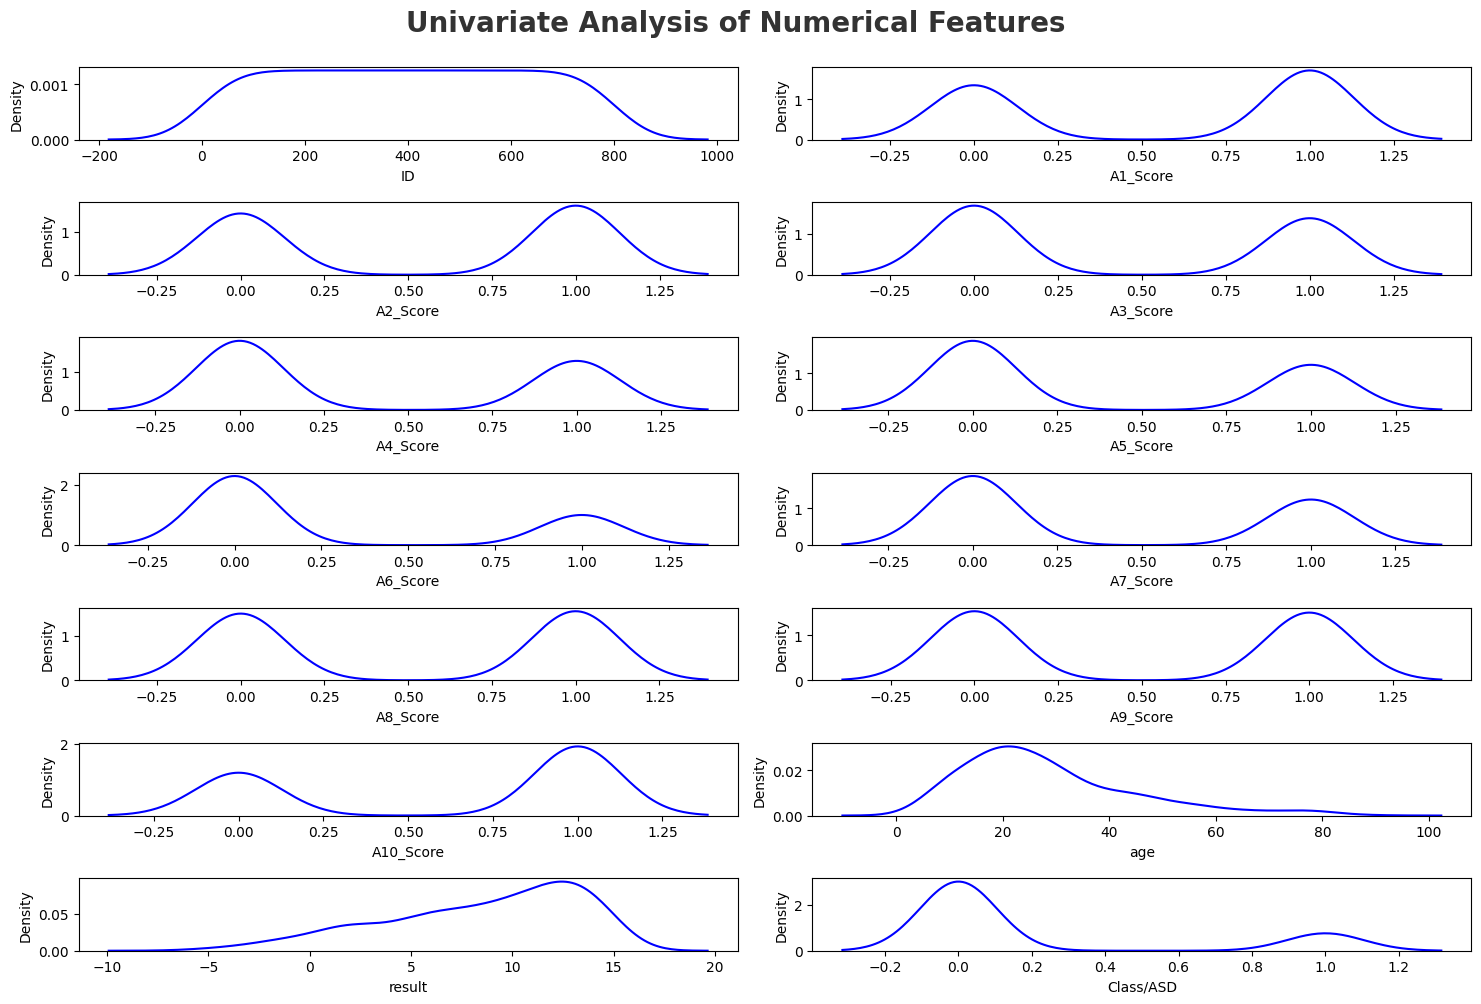

In [10]:
import math

n = len(numeric_features)
cols = 2
rows = math.ceil(n / cols)

plt.figure(figsize=(15, 10))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(n):
    plt.subplot(rows, cols, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])

plt.tight_layout()
plt.show()


**Insights**

*  age column looks more Right-Skewed
*  result is also Right-Skewed
*  Class/ASD is imbalance between 1 and 0

**Categorical Features**

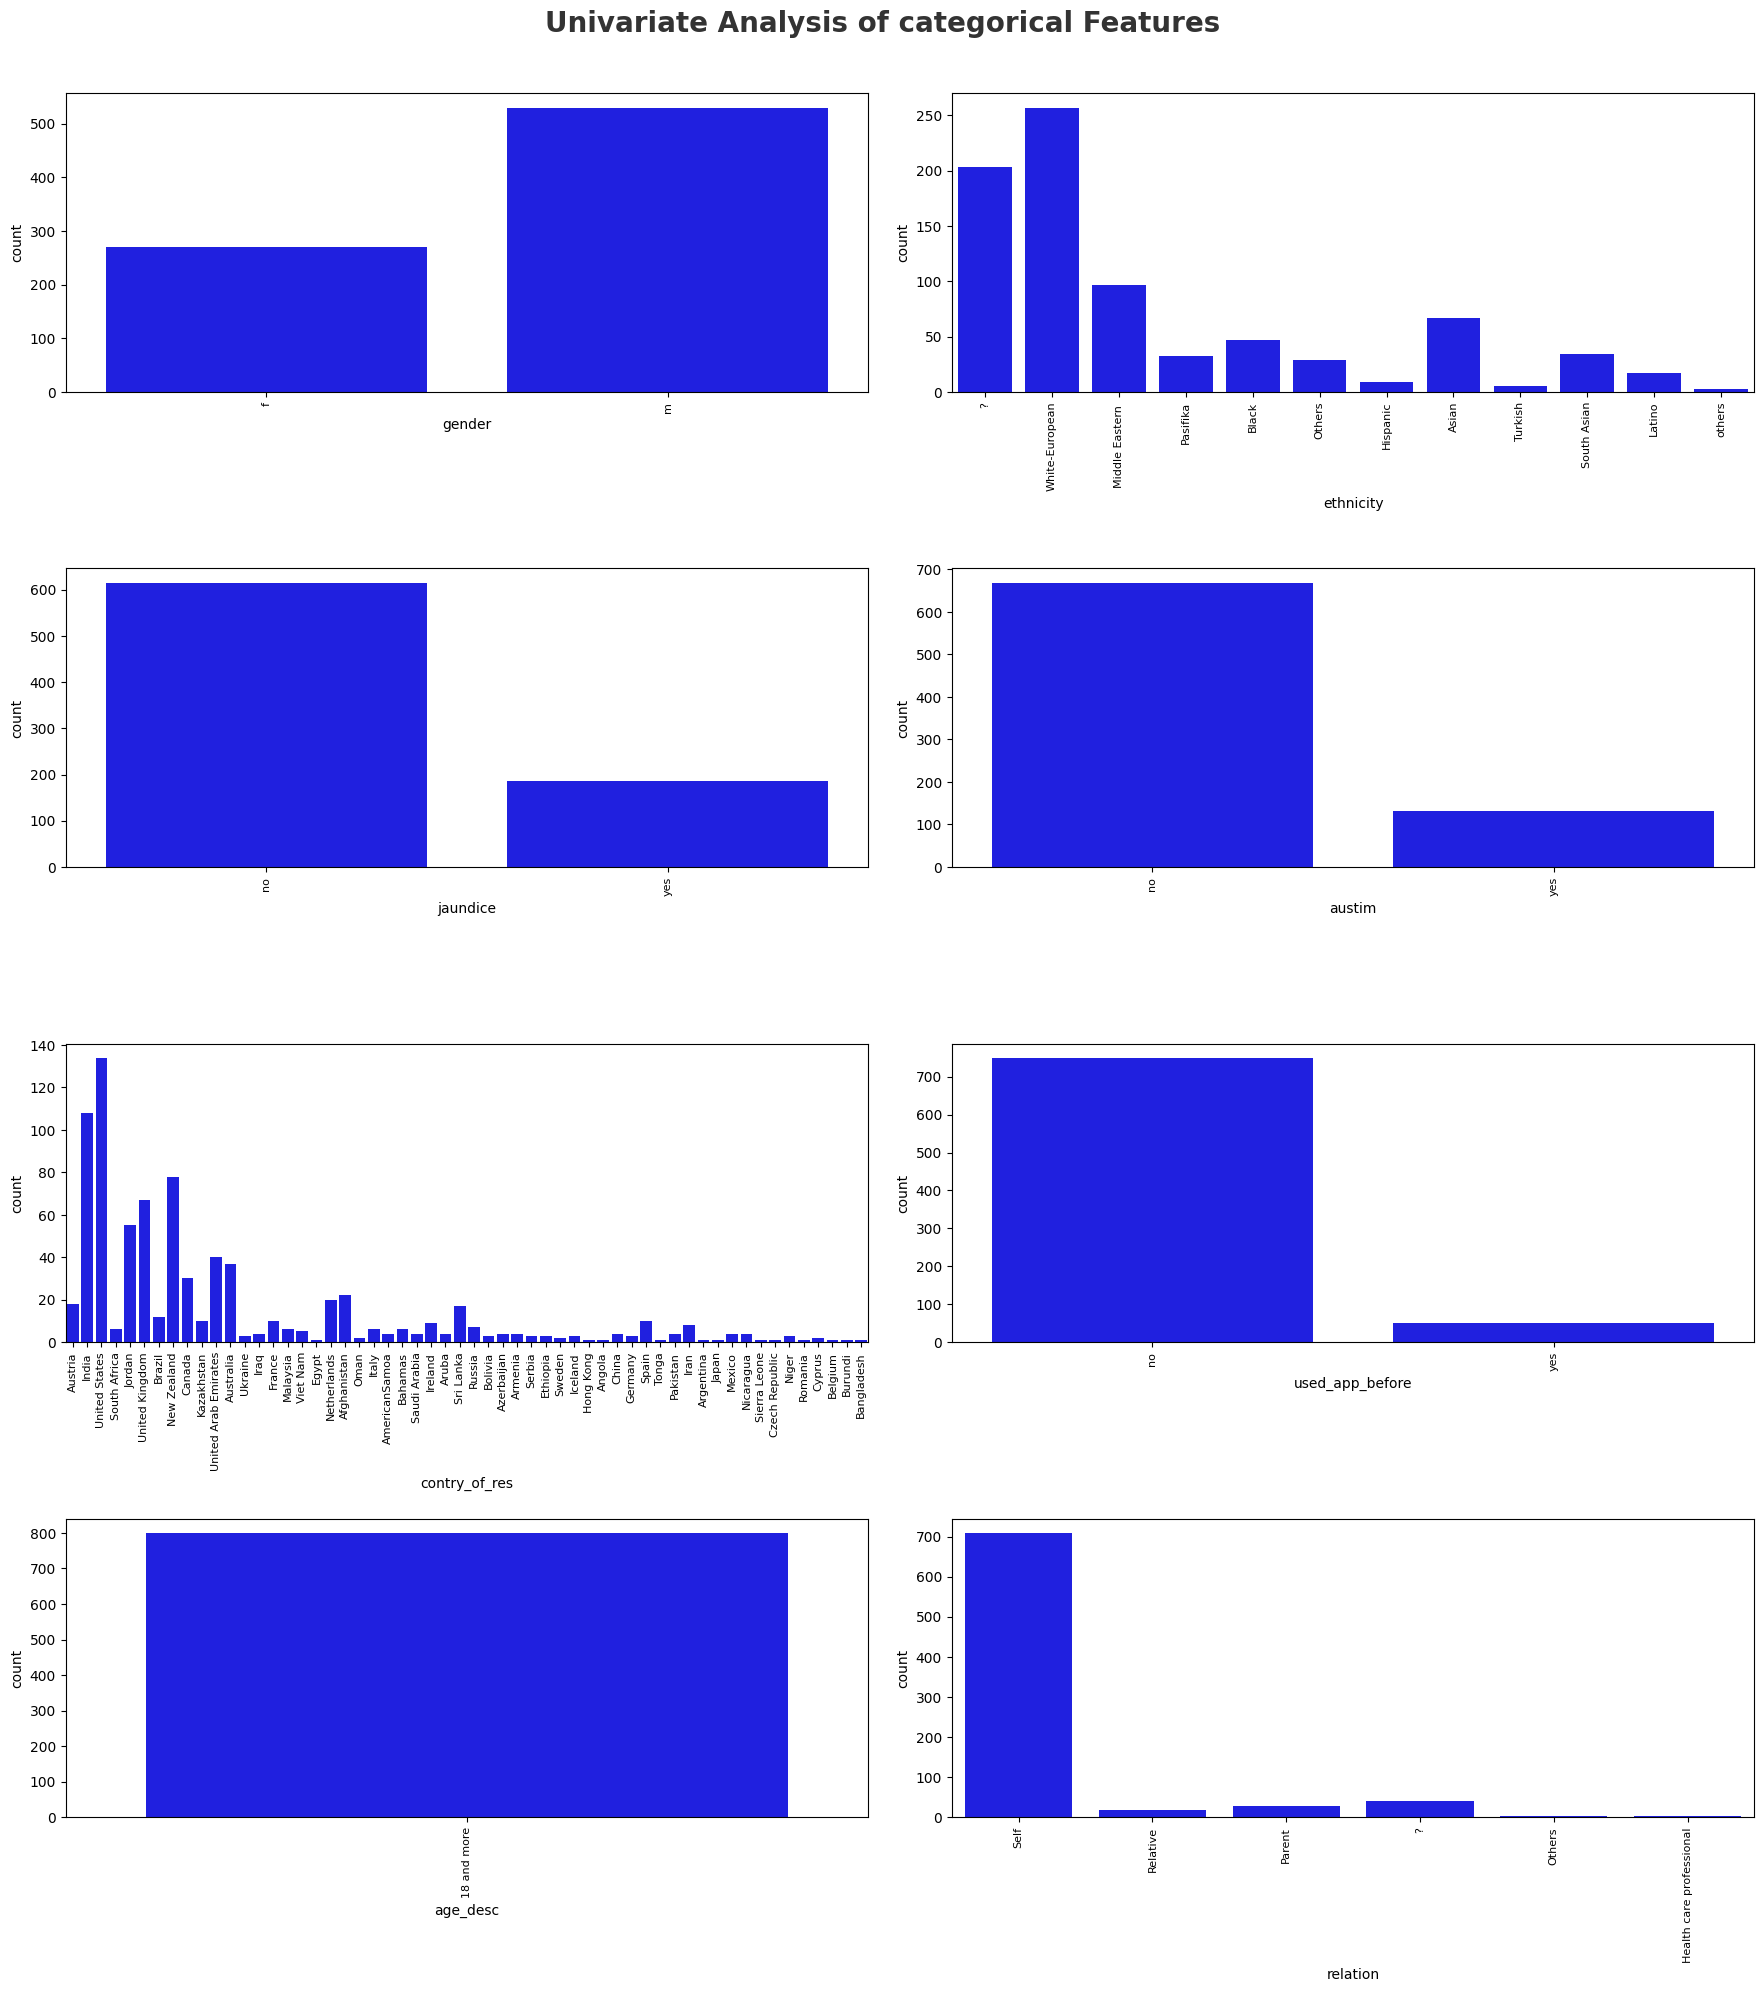

In [12]:
import math

if 'ID' in numeric_features:
    numeric_features.remove('ID')

n = len(categorical_features)
cols = 2
rows = math.ceil(n / cols)

plt.figure(figsize=(18, rows*5))
plt.suptitle('Univariate Analysis of categorical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(n):
    plt.subplot(rows, cols, i+1)
    sns.countplot(x=df[categorical_features[i]], color='blue')
    plt.xlabel(categorical_features[i])
    plt.xticks(rotation=90, fontsize=8)

plt.tight_layout(pad=2.0)
plt.show()

**Insights**

- **Gender:** Male-dominated (66.25% vs 33.75%) — potential bias risk
- **Ethnicity:** White-European and missing ("?") values are the top two categories
- **Jaundice:** Most had no jaundice at birth (76.9%)
- **Austim:** Most have no family history of autism
- **Country of Residence:** High diversity but long-tail imbalance across countries
- **Used App Before:** Most never used the screening app before
- **Relation:** Mostly self-completed; rare categories like "Health care professional"

**Multivariate Analysis**

In [13]:
discrete_features = [feature for feature in numeric_features if len(df[feature].unique())<=25]
continuous_features = [feature for feature in numeric_features if len(df[feature].unique()) > 25]

print('We have {} discrete features : {}'.format(len(discrete_features), discrete_features))
print('We have {} continuous features : {}'.format(len(continuous_features), continuous_features))


We have 11 discrete features : ['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'Class/ASD']
We have 2 continuous features : ['age', 'result']


**Check Multicollinearity in Numerical features**

In [14]:
correlation = df[continuous_features].corr()
print(correlation)

             age    result
age     1.000000 -0.203589
result -0.203589  1.000000


**Insight**:

**No Multicollinearity issue**

**Chi-squared test**

is one way to show a relationship between two categorical variables
test correlation of categorical columns with target 

Null Hypothesis : the feature is independent of target column (no correlation)

Alternative Hypothesis : the feature and target column are dependent (correalted)

In [15]:
from scipy.stats import chi2_contingency
chi2_test = []
for feature in categorical_features:
    if chi2_contingency(pd.crosstab(df['Class/ASD'], df[feature]))[1] < 0.05:
        chi2_test.append('Reject Null Hypothesis')
    else:
        chi2_test.append('Fail to Reject Null Hypothesis')
result = pd.DataFrame(data=[categorical_features , chi2_test]).T
result.columns = ['Column', 'Hypothesis Result']
result

,Column,Hypothesis Result
0,gender,Fail to Reject Null Hypothesis
1,ethnicity,Reject Null Hypothesis
2,jaundice,Reject Null Hypothesis
3,austim,Reject Null Hypothesis
4,contry_of_res,Reject Null Hypothesis
5,used_app_before,Fail to Reject Null Hypothesis
6,age_desc,Fail to Reject Null Hypothesis
7,relation,Fail to Reject Null Hypothesis


**Report**

* gender, used_app_before, age_desc and relation are not correlate with target column

**Cecking Null values**

In [16]:
df.isnull().sum()

ID                 0
A1_Score           0
A2_Score           0
A3_Score           0
A4_Score           0
A5_Score           0
A6_Score           0
A7_Score           0
A8_Score           0
A9_Score           0
A10_Score          0
age                0
gender             0
ethnicity          0
jaundice           0
austim             0
contry_of_res      0
used_app_before    0
result             0
age_desc           0
relation           0
Class/ASD          0
dtype: int64

In [17]:
for col in categorical_features:
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"{col}: {count} missing values ('?')")



ethnicity: 203 missing values ('?')
relation: 40 missing values ('?')


In [18]:
print(df[numeric_features].isnull().sum())


A1_Score     0
A2_Score     0
A3_Score     0
A4_Score     0
A5_Score     0
A6_Score     0
A7_Score     0
A8_Score     0
A9_Score     0
A10_Score    0
age          0
result       0
Class/ASD    0
dtype: int64


In [19]:
continuous_features=[feature for feature in numeric_features if len(df[feature].unique())>=10]
print('Num of continues features : ' , continuous_features)

Num of continues features :  ['age', 'result']


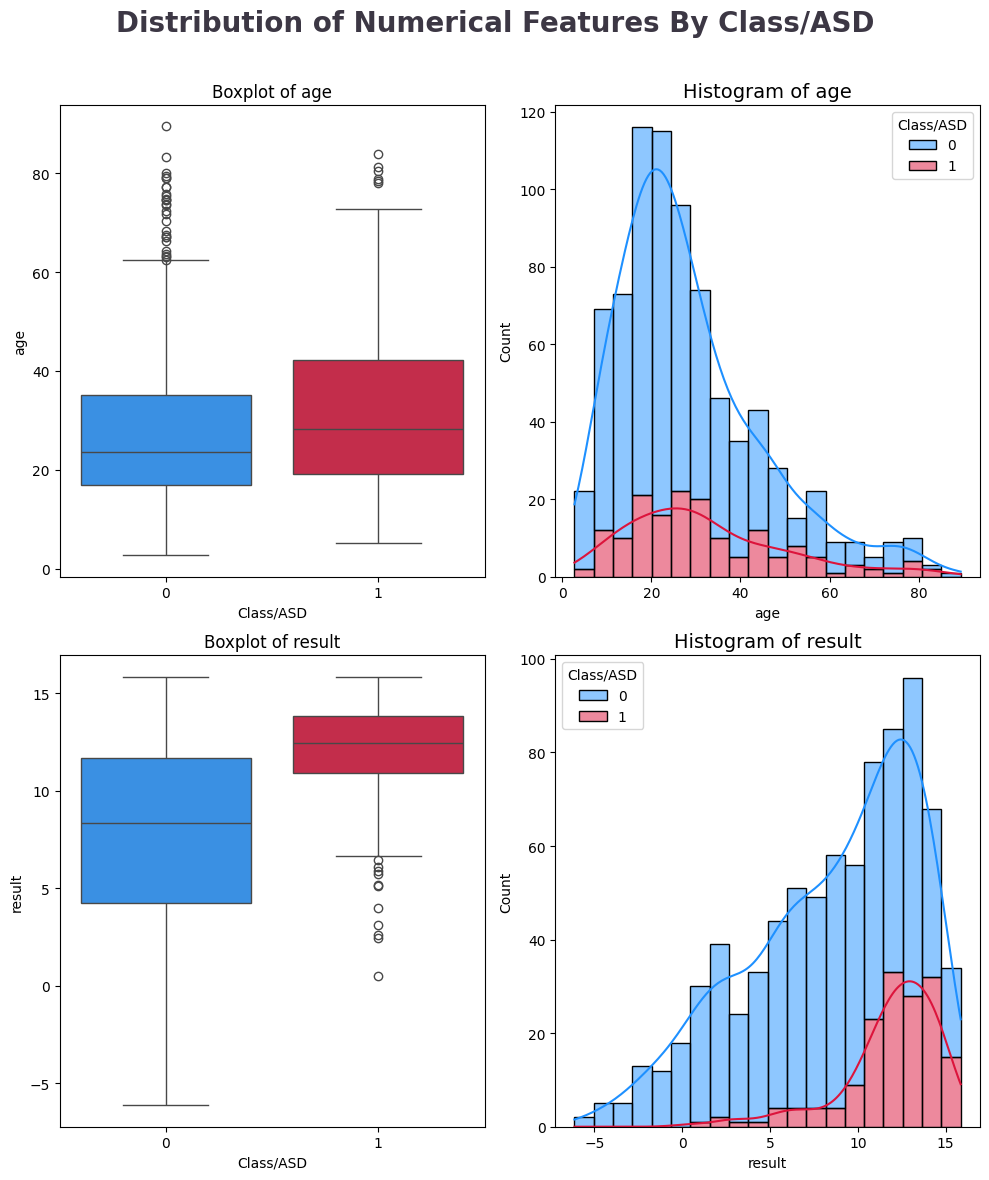

In [20]:
clr1=['#1E90FF', '#DC143C']
fig, ax = plt.subplots(2, 2 ,figsize = (10,12))
fig.suptitle('Distribution of Numerical Features By Class/ASD' , color='#3C3744', fontsize = 20, fontweight='bold', ha='center')

for i, col in enumerate(continuous_features):
    sns.boxplot(data=df, x='Class/ASD', y=col, palette=clr1, ax=ax[i,0])
    ax[i,0].set_title(f'Boxplot of {col}', fontsize=12)
    sns.histplot(data=df, x=col, hue='Class/ASD', bins=20,kde=True,
                 multiple='stack', palette=clr1, ax=ax[i,1])
    ax[i,1].set_title(f'Histogram of {col}', fontsize=14)
fig.tight_layout()
fig.subplots_adjust(top=0.90)

In [23]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]
print(f" the number of outliers in age : {len(outliers)}")
print(f" normal range (without Outliers): {lower_bound:.1f} to {upper_bound:.1f}")
print(outliers['age'].values)


 the number of outliers in age : 35
 normal range (without Outliers): -10.8 to 63.9
[72.83887066 74.87051104 67.00819233 74.53450864 75.87860795 79.43573875
 79.11276316 69.53755283 64.26785425 64.35089943 78.4114102  78.83950028
 77.14998035 68.27279898 81.19065627 73.84664232 80.06084312 67.08256513
 73.54313684 74.4873026  79.11102195 70.27272613 68.24418123 67.53953091
 83.20499393 72.30565349 75.43564613 89.4617183  67.56326151 83.97817937
 71.76154045 77.92832772 77.21061696 66.33610623 80.54408543]


In [24]:
Q1_r = df['result'].quantile(0.25)
Q3_r = df['result'].quantile(0.75)
IQR_r = Q3_r - Q1_r

lower_r = Q1_r - 1.5 * IQR_r
upper_r = Q3_r + 1.5 * IQR_r

outliers_result = df[(df['result'] < lower_r) | (df['result'] > upper_r)]
print(f"\n the number of Outliers in result: {len(outliers_result)}")



 the number of Outliers in result: 1


**Insight**

age weak predictor \
result strong predictor

Initial Analysis

• Dataset: 800 training records, 22 features, binary classification task\
• Target (Class/ASD) shows class imbalance — more non-ASD cases than ASD\
• result is the strongest discriminative feature; age shows weak predictive power\
• Chi-Square tests show gender, used_app_before, age_desc, and relation are not significantly correlated with the target\
• ethnicity has a notable proportion of missing values ("?")\
• No multicollinearity detected between continuous features (age, result)\
** the outliers are valid data points

**4. Visualization**

**4.1 visualize the target feature**

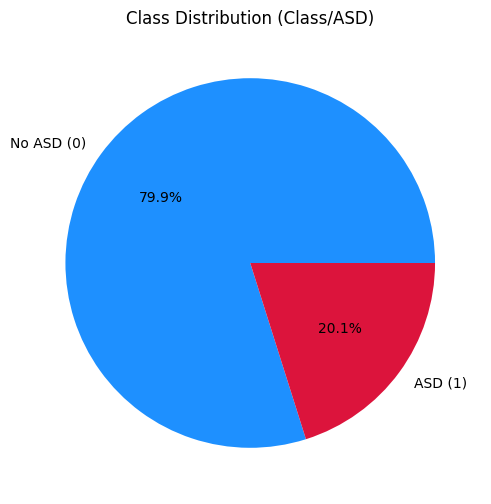

In [25]:
plt.figure(figsize=(6,6))
df['Class/ASD'].value_counts().plot.pie(
    autopct ='%1.1f%%',
    colors=['#1E90FF' , '#DC143C'],
    labels=['No ASD (0)', 'ASD (1)']
)
plt.title('Class Distribution (Class/ASD)')
plt.ylabel('')
plt.show()

* the Target Variable is Imbalanced

**4.2 The Impact of Jaundice on ASD**

In [26]:
df.groupby('jaundice')['Class/ASD'].mean()*100

jaundice
no     17.073171
yes    30.270270
Name: Class/ASD, dtype: float64

**Participants who had jaundice at birth show a notably higher ASD rate (30.27%) compared to those who did not (17.07%)**

**4.3 The Impact Of the family history on ASD**

In [27]:
df.groupby('austim')['Class/ASD'].mean()*100

austim
no     13.751868
yes    52.671756
Name: Class/ASD, dtype: float64

**Family history of autism shows a very strong association with ASD diagnosis**

**4.4 The Impact of ethnicity on ASD**

In [28]:
result = df.groupby('ethnicity')['Class/ASD'].agg(['count', 'sum', 'mean'])
result['mean'] = result['mean']*100
result.sort_values('mean', ascending=False)

,count,sum,mean
ethnicity,,,
White-European,257,121,47.081712
Latino,17,4,23.529412
Hispanic,9,2,22.222222
Pasifika,32,6,18.750000
Black,47,6,12.765957
South Asian,34,3,8.823529
Others,29,2,6.896552
Middle Eastern,97,6,6.185567
Asian,67,4,5.970149


**White-European participants show the highest ASD rate (47.08%) among ethnicities with sufficient sample size (257 records)**
**, suggesting a notable association. However, categories like Turkish and "others" show 0% ASD rate, but this is unreliable due to very small sample sizes (3-5 records) and should not be interpreted as a real effect**

**Final Report**


•Drop weak features: gender, used_app_before, age_desc, relation (not significantly correlated with target per Chi-Square test)

•Handle missing values: ethnicity has ~25% "?" values — needs imputation (e.g., replace with "Unknown")
	
•Address class imbalance: Class/ASD target is imbalanced — use SMOTE or class_weight='balanced' during training
	
•Strongest predictors to keep: result, austim, jaundice, ethnicity, and A1-A10 scores
	
•Weak predictor: age shows little distinction between classes on its own
	
•No multicollinearity: age and result have weak correlation (-0.20) — safe to keep both
	
•No data leakage: result is not a direct sum of A1-A10 (0/800 rows matched) — safe to use together
	
•Outliers in age (64-89 years): real, valid data — should NOT be removed
	
•Encoding required: categorical features (ethnicity, jaundice, austim, contry_of_res) need to be encoded before modeling